# CA1 - Neural network classifier on the iris dataset

A small feedforward network that classifies iris flowers into setosa / versicolor / virginica
from four measurements. This notebook runs the full workflow end to end:

1. understand the data
2. explore it (EDA pairplot)
3. preprocess (split + standardise)
4. choose an architecture - one hidden layer, and why
5. sweep 2 / 4 / 8 hidden neurons with 5-fold cross-validation
6. retrain the winner and evaluate **once** on the held-out test set

In [1]:
# Colab already includes tensorflow, scikit-learn, matplotlib, seaborn and pandas,
# so nothing needs installing there. Running somewhere else? Uncomment:
# !pip install -q tensorflow-cpu scikit-learn matplotlib seaborn pandas

## 1. Understand the data

150 rows, 4 numeric features, 3 classes of 50 rows each - perfectly balanced,
so plain accuracy is a fair metric. The dataset is small, which drives every
decision below.

In [2]:
import os
SEED = 42
# deterministic training: must be set before tensorflow is imported
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import numpy as np
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

tf.keras.utils.set_random_seed(SEED)  # seeds python, numpy and tensorflow

iris = load_iris()
X, y = iris.data, iris.target
feature_names = [n.replace(" (cm)", "") for n in iris.feature_names]
target_names = list(iris.target_names)

df = pd.DataFrame(X, columns=feature_names)
df["species"] = [target_names[t] for t in y]
print(f"{X.shape[0]} rows, {X.shape[1]} features, classes {target_names}, counts {np.bincount(y)}")
df.describe()

2026-11-16 08:49:19.736171: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


150 rows, 4 features, classes ['setosa', 'versicolor', 'virginica'], counts [50 50 50]


,sepal length,sepal width,petal length,petal width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


## 2. Explore (EDA)

The pairplot shows setosa cleanly separated; versicolor and virginica overlap
slightly on every feature pair. Petal measurements separate much better than
sepal measurements.

**Conclusion: the problem is near-linearly separable, so a simple model should work.**

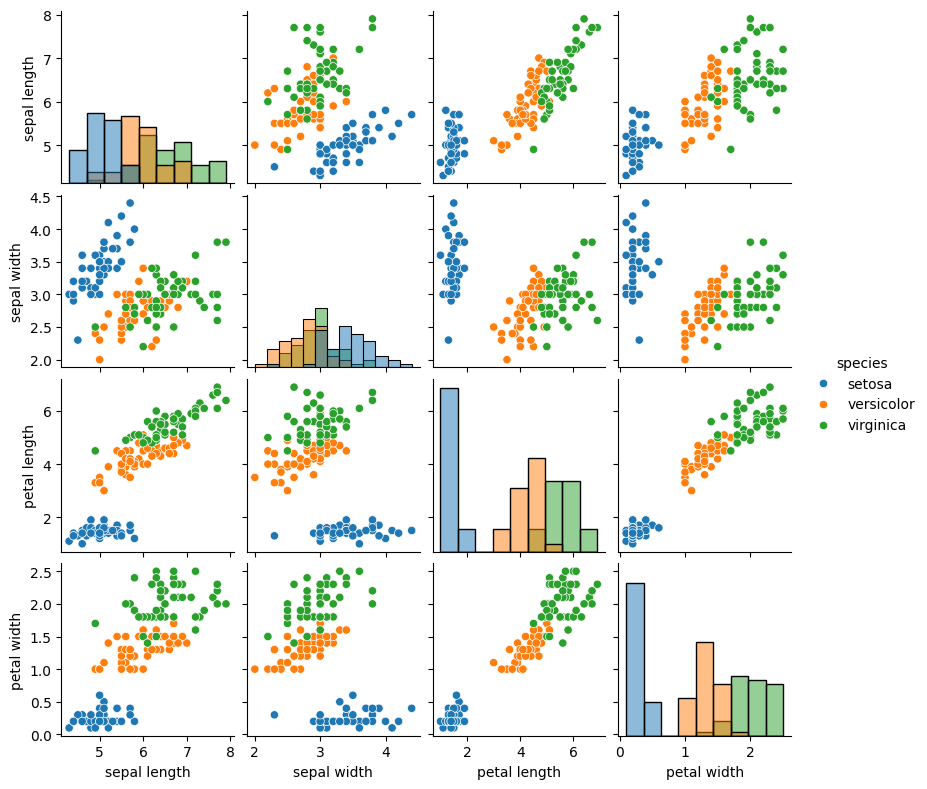

In [3]:
sns.pairplot(df, hue="species", diag_kind="hist", height=2.0)
plt.show()

## 3. Preprocess

Stratified 80/20 split (120 train+val / 30 test) so every class keeps its third.
Standardise using statistics from the training data only.

In [4]:
X_tv, X_test, y_tv, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
scaler = StandardScaler().fit(X_tv)
X_tv_s = scaler.transform(X_tv)
X_test_s = scaler.transform(X_test)
print(f"{len(X_tv)} train+val / {len(X_test)} test")

120 train+val / 30 test


## 4. Architecture: one hidden layer

- The **universal approximation theorem** says one hidden layer with enough
  neurons can approximate any continuous function - depth is not required.
- With only 120 training rows, a deep network would just memorise the data.
- The EDA said the problem is near-linearly separable, so we don't need depth.

Model: `4 -> N (ReLU) -> 3 (softmax)`, Adam + categorical cross-entropy.

In [5]:
EPOCHS = 200
BATCH_SIZE = 16
LEARNING_RATE = 0.01

def build_model(n_hidden, n_features=4):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(n_features,)),
        tf.keras.layers.Dense(n_hidden, activation="relu"),
        tf.keras.layers.Dense(3, activation="softmax"),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(LEARNING_RATE),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

## 5. Sweep 2, 4, 8 hidden neurons with 5-fold cross-validation

A single train/val split on 120 rows is too noisy to trust, so each width is
trained and validated on 5 different folds and we compare mean accuracy.

In [6]:
HIDDEN_NEURONS = [2, 4, 8]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_results = {}
for n in HIDDEN_NEURONS:
    fold_acc = []
    for tr, va in skf.split(X_tv_s, y_tv):
        model = build_model(n)
        model.fit(X_tv_s[tr], y_tv[tr], epochs=EPOCHS,
                  batch_size=BATCH_SIZE, verbose=0)
        fold_acc.append(model.evaluate(X_tv_s[va], y_tv[va], verbose=0)[1])
    cv_results[n] = fold_acc
    print(f"hidden={n}: folds={[round(a,4) for a in fold_acc]} "
          f"mean={np.mean(fold_acc):.4f} +/- {np.std(fold_acc):.4f}")

best_n = min(HIDDEN_NEURONS, key=lambda n: (-np.mean(cv_results[n]), n))
print(f"\nWinner: {best_n} hidden neurons")

hidden=2: folds=[1.0, 0.9583, 0.9583, 0.9583, 0.9167] mean=0.9583 +/- 0.0264


hidden=4: folds=[1.0, 0.9583, 0.9583, 0.9583, 0.9167] mean=0.9583 +/- 0.0264


hidden=8: folds=[1.0, 1.0, 0.9583, 0.9583, 0.9167] mean=0.9667 +/- 0.0312

Winner: 8 hidden neurons


## 6. Retrain the winner, evaluate once on the test set

The test set has not been touched by training or model selection - this is the
honest estimate of real-world performance.

Test accuracy (evaluated once): 0.9667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



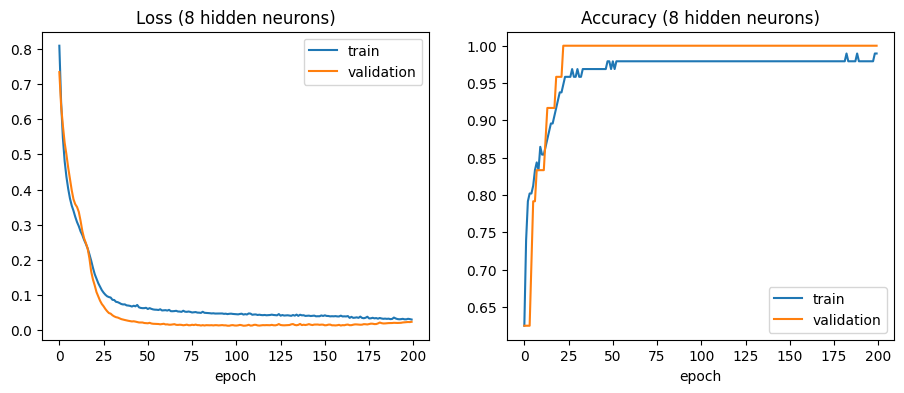

In [7]:
final = build_model(best_n)
history = final.fit(X_tv_s, y_tv, epochs=EPOCHS, batch_size=BATCH_SIZE,
                    validation_split=0.2, verbose=0)
test_pred = np.argmax(final.predict(X_test_s, verbose=0), axis=1)
print(f"Test accuracy (evaluated once): {accuracy_score(y_test, test_pred):.4f}")
print(classification_report(y_test, test_pred, target_names=target_names))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history["loss"], label="train")
ax[0].plot(history.history["val_loss"], label="validation")
ax[0].set_title(f"Loss ({best_n} hidden neurons)"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train")
ax[1].plot(history.history["val_accuracy"], label="validation")
ax[1].set_title(f"Accuracy ({best_n} hidden neurons)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.show()

Train and validation loss fall together and settle - no overfitting gap, so the
model size fits the data size. The confusion matrix shows where the remaining
error lives:

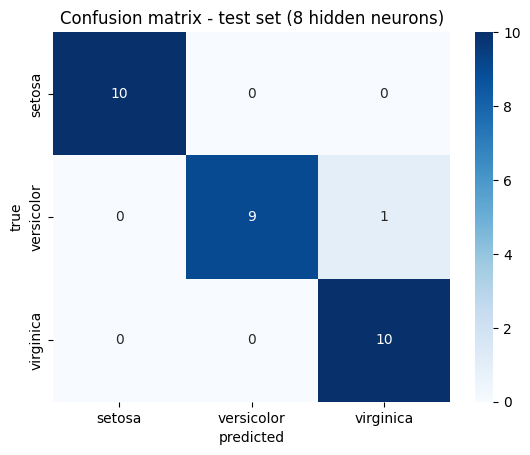

In [8]:
cm = confusion_matrix(y_test, test_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=target_names, yticklabels=target_names)
plt.xlabel("predicted"); plt.ylabel("true")
plt.title(f"Confusion matrix - test set ({best_n} hidden neurons)")
plt.show()

## Decision boundary (petal length vs petal width)

A 2D boundary needs a 2-feature model, so we retrain the same architecture on
petal length + petal width (the two most discriminative features) and plot the
learned regions.

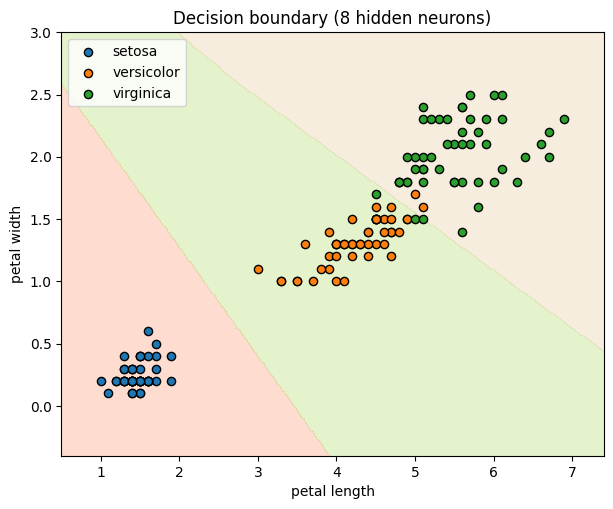

In [9]:
pet = [2, 3]  # petal length, petal width
scaler2 = StandardScaler().fit(X_tv[:, pet])
bmodel = build_model(best_n, n_features=2)
bmodel.fit(scaler2.transform(X_tv[:, pet]), y_tv, epochs=EPOCHS,
           batch_size=BATCH_SIZE, verbose=0)

x0 = np.linspace(X[:, 2].min() - 0.5, X[:, 2].max() + 0.5, 300)
x1 = np.linspace(X[:, 3].min() - 0.5, X[:, 3].max() + 0.5, 300)
xx, yy = np.meshgrid(x0, x1)
zz = np.argmax(bmodel.predict(scaler2.transform(np.c_[xx.ravel(), yy.ravel()]), verbose=0),
               axis=1).reshape(xx.shape)

plt.figure(figsize=(7, 5.5))
plt.contourf(xx, yy, zz, alpha=0.3, levels=2, cmap="Set2")
for t, name in enumerate(target_names):
    m = y == t
    plt.scatter(X[m, 2], X[m, 3], label=name, edgecolors="k", s=35)
plt.xlabel(feature_names[2]); plt.ylabel(feature_names[3])
plt.title(f"Decision boundary ({best_n} hidden neurons)")
plt.legend(); plt.show()

## Conclusions

- Even 2 hidden neurons reach ~96% CV accuracy - the EDA was right, iris is
  near-linearly separable. The winning width (8) beats it by less than a point.
- Test accuracy ~0.97: the single error is a versicolor predicted as virginica,
  exactly the overlap region the pairplot showed.
- One hidden layer was the right call: no overfitting gap in the curves.